[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shahin1717/ai-roadmap/blob/main/math/linear-algebra/vectors-and-matrices/notebook.ipynb)

# Vectors and Matrices: hands-on

This notebook goes with the [topic README](README.md). You will **draw** vectors, build linear combinations, measure angles with the dot product, and watch a matrix transform the plane. It needs only NumPy and Matplotlib and runs in a few seconds on a CPU.

Run the cells from top to bottom. After each demo, change a number and run it again: playing with the numbers is the fastest way to build intuition.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 70
plt.rcParams["axes.titlesize"] = 11
np.set_printoptions(precision=3, suppress=True)

## 1. Vectors as arrows

In NumPy a vector is a one-dimensional array. We also define two small drawing helpers that we will reuse.

In [2]:
def setup_axes(ax, lim=(-1, 6), title=""):
    """Square axes with a light grid and the two coordinate axes drawn in."""
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    ax.set_aspect("equal")
    ax.axhline(0, color="gray", lw=0.8)
    ax.axvline(0, color="gray", lw=0.8)
    ax.grid(alpha=0.3)
    ax.set_title(title)


def arrow(ax, vec, start=(0, 0), color="C0", label=None, ls="-"):
    """Draw `vec` as an arrow beginning at `start`."""
    end = np.asarray(start) + np.asarray(vec)
    ax.annotate("", xy=end, xytext=start,
                arrowprops=dict(arrowstyle="->", color=color, lw=2, ls=ls))
    if label:
        mid = np.asarray(start) + np.asarray(vec) / 2
        ax.text(mid[0] + 0.1, mid[1] + 0.15, label, color=color, fontsize=12)

**Adding vectors.** Place the tail of $\mathbf{w}$ at the tip of $\mathbf{v}$. The sum $\mathbf{v}+\mathbf{w}$ is the arrow from the start to where you end up. The dashed arrows complete a parallelogram: going $\mathbf{w}$ first and then $\mathbf{v}$ lands on the same spot.

v + w = [4 3]


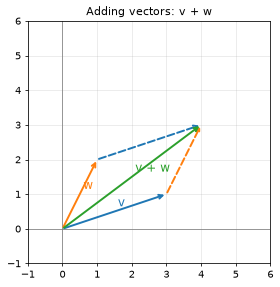

In [3]:
v = np.array([3, 1])
w = np.array([1, 2])
print("v + w =", v + w)

fig, ax = plt.subplots(figsize=(4.5, 4.5))
setup_axes(ax, title="Adding vectors: v + w")
arrow(ax, v, color="C0", label="v")
arrow(ax, w, color="C1", label="w")
arrow(ax, w, start=v, color="C1", ls="--")
arrow(ax, v, start=w, color="C0", ls="--")
arrow(ax, v + w, color="C2", label="v + w")
plt.show()

**Scaling a vector.** Multiplying by a number stretches or shrinks the arrow. A negative number flips it around the origin.

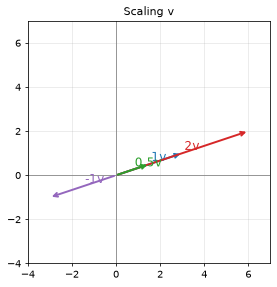

In [4]:
fig, ax = plt.subplots(figsize=(4.5, 4.5))
setup_axes(ax, lim=(-4, 7), title="Scaling v")
for c, color in [(1, "C0"), (2, "C3"), (0.5, "C2"), (-1, "C4")]:
    arrow(ax, c * v, color=color, label=f"{c}v")
plt.show()

## 2. Linear combinations

A **linear combination** of $\mathbf{v}$ and $\mathbf{w}$ is $c\,\mathbf{v} + d\,\mathbf{w}$ for any numbers $c$ and $d$. Below, four different choices of $(c, d)$ give four different arrows.

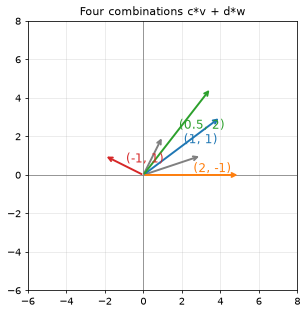

In [5]:
fig, ax = plt.subplots(figsize=(5, 5))
setup_axes(ax, lim=(-6, 8), title="Four combinations c*v + d*w")
arrow(ax, v, color="gray")
arrow(ax, w, color="gray")
for (c, d), color in [((1, 1), "C0"), ((2, -1), "C1"), ((0.5, 2), "C2"), ((-1, 1), "C3")]:
    arrow(ax, c * v + d * w, color=color, label=f"({c}, {d})")
plt.show()

What happens if we try **all** the combinations? Here are 400 of them, with $c$ and $d$ ranging from $-3$ to $3$. Because $\mathbf{v}$ and $\mathbf{w}$ point in different directions, the combinations cover the whole plane.

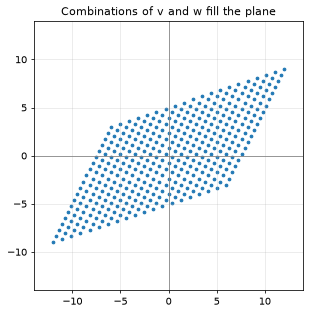

In [6]:
cs, ds = np.meshgrid(np.linspace(-3, 3, 20), np.linspace(-3, 3, 20))
points = cs.ravel()[:, None] * v + ds.ravel()[:, None] * w   # one row per (c, d) pair

fig, ax = plt.subplots(figsize=(5, 5))
setup_axes(ax, lim=(-14, 14), title="Combinations of v and w fill the plane")
ax.scatter(points[:, 0], points[:, 1], s=8)
plt.show()

Now try two vectors that point along the **same** line, for example $\mathbf{v}$ and $2\mathbf{v}$. Their combinations can only reach points on that line.

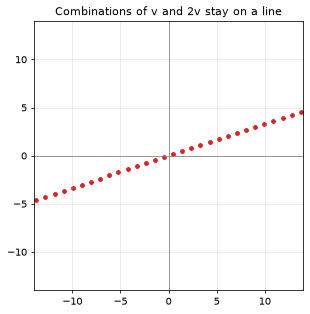

In [7]:
u = 2 * v
points = cs.ravel()[:, None] * v + ds.ravel()[:, None] * u

fig, ax = plt.subplots(figsize=(5, 5))
setup_axes(ax, lim=(-14, 14), title="Combinations of v and 2v stay on a line")
ax.scatter(points[:, 0], points[:, 1], s=8, color="C3")
plt.show()

## 3. Length and the dot product

The length of a vector is $\sqrt{v_1^2 + v_2^2 + \dots}$. The dot product multiplies matching entries and adds them up. We compute both by hand and then with NumPy to see they agree.

In [8]:
v = np.array([3.0, 4.0])
w = np.array([4.0, -3.0])

length_by_hand = np.sqrt(v[0] ** 2 + v[1] ** 2)
dot_by_hand = v[0] * w[0] + v[1] * w[1]

print("length of v: by hand =", length_by_hand, "| NumPy =", np.linalg.norm(v))
print("v . w:       by hand =", dot_by_hand, "| NumPy =", np.dot(v, w))

assert np.isclose(length_by_hand, np.linalg.norm(v))
assert np.isclose(dot_by_hand, v @ w)   # `@` also computes the dot product of two vectors

length of v: by hand = 5.0 | NumPy = 5.0
v . w:       by hand = 0.0 | NumPy = 0.0


The geometric meaning: $\mathbf{v}\cdot\mathbf{w} = \|\mathbf{v}\|\,\|\mathbf{w}\|\cos\theta$. Solving for the angle gives the function below. The three panels show a positive, a zero, and a negative dot product.

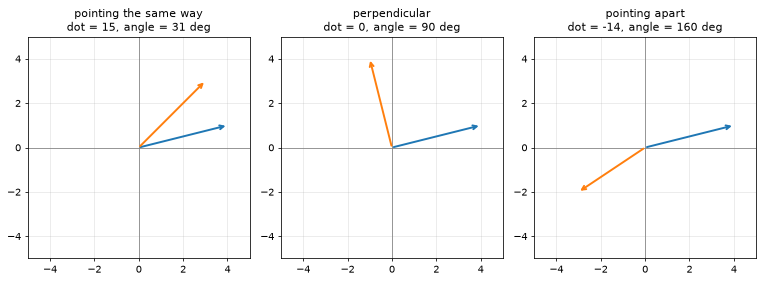

In [9]:
def angle_degrees(a, b):
    """Angle between two vectors, from  a . b = |a| |b| cos(theta)."""
    cos_theta = (a @ b) / (np.linalg.norm(a) * np.linalg.norm(b))
    return np.degrees(np.arccos(np.clip(cos_theta, -1, 1)))   # clip guards against rounding just past +-1


a = np.array([4.0, 1.0])
pairs = [
    ("pointing the same way", a, np.array([3.0, 3.0])),
    ("perpendicular", a, np.array([-1.0, 4.0])),
    ("pointing apart", a, np.array([-3.0, -2.0])),
]

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for ax, (name, x, y) in zip(axes, pairs):
    setup_axes(ax, lim=(-5, 5), title=f"{name}\ndot = {x @ y:.0f}, angle = {angle_degrees(x, y):.0f} deg")
    arrow(ax, x, color="C0")
    arrow(ax, y, color="C1")
plt.tight_layout()
plt.show()

### Cosine similarity with toy embeddings

In AI, things like words are turned into vectors called **embeddings**, so that similar things get similar directions. The numbers below are **invented** for this demo (real embeddings are learned from data and have hundreds of entries). Each vector has three numbers: how animal-like, how vehicle-like, and how big the thing is.

Cosine similarity is the dot product divided by both lengths, so it only compares directions.

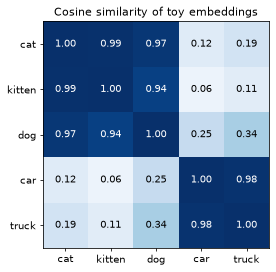

In [10]:
words = ["cat", "kitten", "dog", "car", "truck"]
E = np.array([
    [0.90, 0.00, 0.2],   # cat
    [0.95, 0.00, 0.1],   # kitten
    [0.80, 0.00, 0.4],   # dog
    [0.00, 0.90, 0.6],   # car
    [0.05, 0.95, 0.9],   # truck
])

E_unit = E / np.linalg.norm(E, axis=1, keepdims=True)   # divide each row by its own length
similarity = E_unit @ E_unit.T                          # every pair of dot products at once

fig, ax = plt.subplots(figsize=(4.8, 4.2))
im = ax.imshow(similarity, vmin=0, vmax=1, cmap="Blues")
ax.set_xticks(range(len(words)), words)
ax.set_yticks(range(len(words)), words)
for i in range(len(words)):
    for j in range(len(words)):
        ax.text(j, i, f"{similarity[i, j]:.2f}", ha="center", va="center",
                color="white" if similarity[i, j] > 0.6 else "black")
ax.set_title("Cosine similarity of toy embeddings")
plt.show()

Animals are similar to animals and vehicles to vehicles, exactly what we wanted. One matrix product, `E_unit @ E_unit.T`, produced all 25 dot products at once.

## 4. Matrices and matrix-vector multiplication

A matrix is a grid of numbers. We multiply it by a vector in two ways: **rows** (each answer entry is a dot product) and **columns** (a linear combination of the columns). Both must give the same result.

In [11]:
A = np.array([[1, 2],
              [3, 4]])
x = np.array([2, 1])

# Row view: one dot product per row of A
row_view = np.array([A[0] @ x, A[1] @ x])

# Column view: x[0] copies of column 0, plus x[1] copies of column 1
column_view = x[0] * A[:, 0] + x[1] * A[:, 1]

print("row view    :", row_view)
print("column view :", column_view)
print("A @ x       :", A @ x)

assert np.array_equal(row_view, column_view)
assert np.array_equal(row_view, A @ x)

row view    : [ 4 10]
column view : [ 4 10]
A @ x       : [ 4 10]


### A matrix is a machine that moves points

Feed a vector into a matrix and you get a new vector out. To *see* what a matrix does, we apply it to a whole shape, a letter F, whose points are the columns of a $2 \times n$ matrix. Then `M @ F` transforms every point at once (this is matrix-matrix multiplication). The F makes it easy to spot rotations and flips.

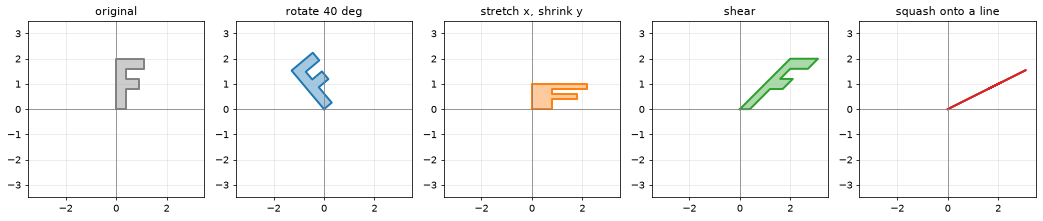

In [12]:
# The corner points of a letter F, one point per column (a 2 x 10 matrix)
F = np.array([[0, 0.4, 0.4, 0.9, 0.9, 0.4, 0.4, 1.1, 1.1, 0],
              [0, 0,   0.8, 0.8, 1.2, 1.2, 1.6, 1.6, 2.0, 2.0]])


def draw_shape(ax, points, color="C0", title=""):
    """Draw the polygon whose corners are the columns of `points`."""
    closed = np.hstack([points, points[:, :1]])   # repeat the first corner to close the outline
    ax.fill(closed[0], closed[1], color=color, alpha=0.4)
    ax.plot(closed[0], closed[1], color=color, lw=2)
    setup_axes(ax, lim=(-3.5, 3.5), title=title)


theta = np.radians(40)
machines = {
    "original": np.eye(2),   # the identity matrix changes nothing
    "rotate 40 deg": np.array([[np.cos(theta), -np.sin(theta)],
                               [np.sin(theta),  np.cos(theta)]]),
    "stretch x, shrink y": np.array([[2.0, 0.0],
                                     [0.0, 0.5]]),
    "shear": np.array([[1.0, 1.0],
                       [0.0, 1.0]]),
    "squash onto a line": np.array([[1.0, 1.0],
                                    [0.5, 0.5]]),
}

fig, axes = plt.subplots(1, 5, figsize=(15, 3.4))
for ax, (name, M), color in zip(axes, machines.items(), ["gray", "C0", "C1", "C2", "C3"]):
    draw_shape(ax, M @ F, color=color, title=name)
plt.tight_layout()
plt.show()

Look at the last panel: that matrix squashes the whole plane onto a single line, so the F is flattened and no matrix can ever undo it. We will understand why when we study vector spaces and rank.

## 5. Multiplying two matrices

The shapes must fit: $(m \times n)\,(n \times p)$ gives $m \times p$.

In [13]:
P = np.ones((2, 3))
Q = np.ones((3, 4))
print("(2 x 3) @ (3 x 4) has shape", (P @ Q).shape)

R = np.ones((3, 2))
try:
    R @ Q
except ValueError:
    print("(3 x 2) @ (3 x 4) fails: the inner numbers 2 and 3 do not match")

(2 x 3) @ (3 x 4) has shape (2, 4)
(3 x 2) @ (3 x 4) fails: the inner numbers 2 and 3 do not match


**Order matters.** Doing "stretch, then rotate" is not the same as "rotate, then stretch". Matrix multiplication captures this: `rotate @ stretch` means *stretch first, then rotate* (the matrix nearest the vector acts first).

rotate @ stretch =
 [[ 1.532 -0.321]
 [ 1.286  0.383]]
stretch @ rotate =
 [[ 1.532 -1.286]
 [ 0.321  0.383]]


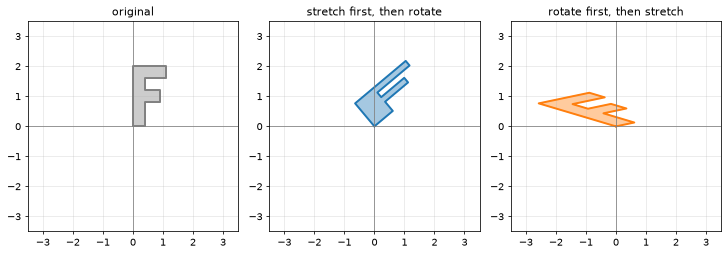

In [14]:
rotate = machines["rotate 40 deg"]
stretch = machines["stretch x, shrink y"]

print("rotate @ stretch =\n", rotate @ stretch)
print("stretch @ rotate =\n", stretch @ rotate)
assert not np.allclose(rotate @ stretch, stretch @ rotate)

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.6))
draw_shape(axes[0], F, color="gray", title="original")
draw_shape(axes[1], rotate @ stretch @ F, color="C0", title="stretch first, then rotate")
draw_shape(axes[2], stretch @ rotate @ F, color="C1", title="rotate first, then stretch")
plt.tight_layout()
plt.show()

## 6. A neural network layer is a matrix

A layer computes $\mathbf{y} = \text{ReLU}(W\mathbf{x} + \mathbf{b})$. Here are the numbers from exercise 8, so you can check your pencil-and-paper answer.

In [15]:
def relu(z):
    """Replace every negative entry by 0."""
    return np.maximum(z, 0)


W = np.array([[1, 0, -1],
              [2, 1, 0]])
b = np.array([1, -10])
x = np.array([3, 2, 1])

print("W x       =", W @ x)
print("W x + b   =", W @ x + b)
print("y (ReLU)  =", relu(W @ x + b))

# Each output is one 'neuron': a dot product of one row of W with the input
by_neuron = np.array([W[i] @ x for i in range(W.shape[0])])
assert np.array_equal(by_neuron, W @ x)

W x       = [2 8]
W x + b   = [ 3 -2]
y (ReLU)  = [3 0]


**A whole batch at once.** Put several inputs side by side as the columns of a matrix `X`. One matrix product then runs all of them through the layer. (Adding `b[:, None]` turns the bias into a column so it is added to every input.)

In [16]:
X = np.array([[3, 0],
              [2, 1],
              [1, 2]])          # two inputs, one per column

Y = relu(W @ X + b[:, None])
print("X has shape", X.shape, "-> Y has shape", Y.shape)
print(Y)

assert np.array_equal(Y[:, 0], relu(W @ x + b))   # first column matches the single-input answer

X has shape (3, 2) -> Y has shape (2, 2)
[[3 0]
 [0 0]]


## Recap and next steps

- A vector is a list of numbers you can picture as an arrow. You can add vectors and scale them, and mixing the two gives **linear combinations**.
- The **dot product** measures how much two vectors point the same way. Divide by the lengths and you get **cosine similarity**, the workhorse of search and embeddings.
- A matrix times a vector is either a stack of dot products (rows) or a linear combination (columns). A matrix is also a machine that moves points.
- Matrix multiplication needs matching inner shapes, and **order matters**.
- A neural network layer is a matrix product plus a bias, followed by a simple non-linear function.

**Try it yourself:** redo the F demos with your own $2\times2$ matrix. Can you find one that reflects the F, or one that rotates it by 90 degrees? Then try the [exercises](exercises/problems.md) and the [assignment](assignment.md).

Next topic: [Linear Equations and Gaussian Elimination](../linear-equations-and-gaussian-elimination/README.md).